In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [2]:
#Load the data

data = pd.read_csv(r"Data\amazon_alexa.tsv", delimiter = '\t', quoting = 3)

print(f"Dataset shape : {data.shape}")

Dataset shape : (3150, 5)


In [16]:
X_text = data['verified_reviews'].fillna('')
y = data['feedback']

In [5]:
print(y.value_counts())
print()
print(y.value_counts(normalize=True) * 100)

feedback
1    2893
0     257
Name: count, dtype: int64

feedback
1    91.84127
0     8.15873
Name: proportion, dtype: float64


In [11]:
duplicate_count = X_text.duplicated().sum()

print("Duplicate reviews:", duplicate_count)

Duplicate reviews: 849


In [12]:
model_data = data.drop_duplicates(
    subset='verified_reviews'
).copy()

print("Original shape:", data.shape)
print("After removing duplicate reviews:", model_data.shape)

Original shape: (3150, 5)
After removing duplicate reviews: (2301, 5)


In [ ]:
X_text = model_data['verified_reviews'].fillna('')
y = model_data['feedback']

In [14]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.30,
    random_state=15,
    stratify=y
)

In [12]:
print("Training distribution:")
print(y_train.value_counts())

print("\nTest distribution:")
print(y_test.value_counts())

Training distribution:
feedback
1    1466
0     144
Name: count, dtype: int64

Test distribution:
feedback
1    629
0     62
Name: count, dtype: int64


In [14]:
print("\nTraining percentage:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTest percentage:")
print(y_test.value_counts(normalize=True) * 100)


Training percentage:
feedback
1    91.055901
0     8.944099
Name: proportion, dtype: float64

Test percentage:
feedback
1    91.027496
0     8.972504
Name: proportion, dtype: float64


In [15]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

In [16]:
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

In [17]:
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (1610, 5000)
Testing shape: (691, 5000)


In [ ]:
def evaluate_model(model, X_train, X_test, y_train, y_test, model_name):
    
    # Train
    model.fit(X_train, y_train)
    
    # Predict
    y_pred = model.predict(X_test)
    
    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    macro_f1 = f1_score(
        y_test,
        y_pred,
        average='macro',
        zero_division=0
    )
    
    print("=" * 60)
    print(model_name)
    print("=" * 60)
    
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print(f"Macro F1 : {macro_f1:.4f}")
    
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Negative', 'Positive']
    )
    
    disp.plot()
    plt.title(f'Confusion Matrix - {model_name}')
    plt.show()
    
    return {
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1': f1,
        'Macro F1': macro_f1,
        'Predictions': y_pred
    } 

### Balanced Logistic Regression

Logistic Regression - Balanced
Accuracy : 0.9117
Precision: 0.9581
Recall   : 0.9444
F1 Score : 0.9512
Macro F1 : 0.7463

Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.58      0.54        62
           1       0.96      0.94      0.95       629

    accuracy                           0.91       691
   macro avg       0.73      0.76      0.75       691
weighted avg       0.92      0.91      0.91       691



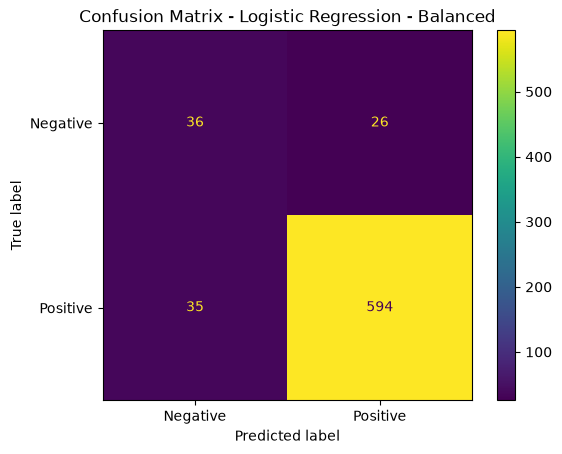

In [20]:
lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=15
)

lr_balanced_result = evaluate_model(
    lr_balanced,
    X_train,
    X_test,
    y_train,
    y_test,
    'Logistic Regression - Balanced'
)

### Balanced SVM

Linear SVM - Balanced
Accuracy : 0.9305
Precision: 0.9504
Recall   : 0.9746
F1 Score : 0.9623
Macro F1 : 0.7589

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.48      0.56        62
           1       0.95      0.97      0.96       629

    accuracy                           0.93       691
   macro avg       0.80      0.73      0.76       691
weighted avg       0.92      0.93      0.93       691



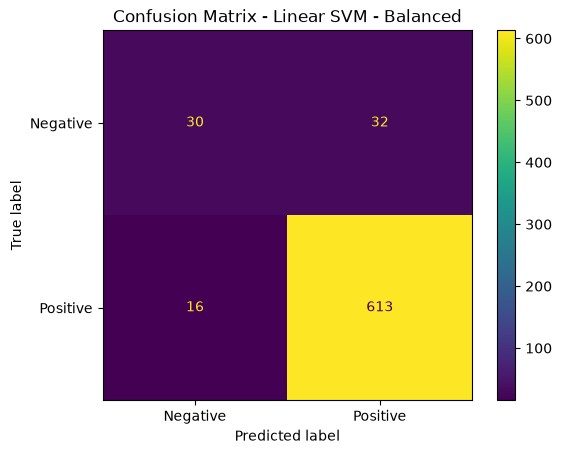

In [21]:
svm = LinearSVC(
    class_weight='balanced',
    random_state=15
)

svm_result = evaluate_model(
    svm,
    X_train,
    X_test,
    y_train,
    y_test,
    'Linear SVM - Balanced'
)

### Naive Bayes

Multinomial Naive Bayes
Accuracy : 0.9103
Precision: 0.9103
Recall   : 1.0000
F1 Score : 0.9530
Macro F1 : 0.4765

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        62
           1       0.91      1.00      0.95       629

    accuracy                           0.91       691
   macro avg       0.46      0.50      0.48       691
weighted avg       0.83      0.91      0.87       691



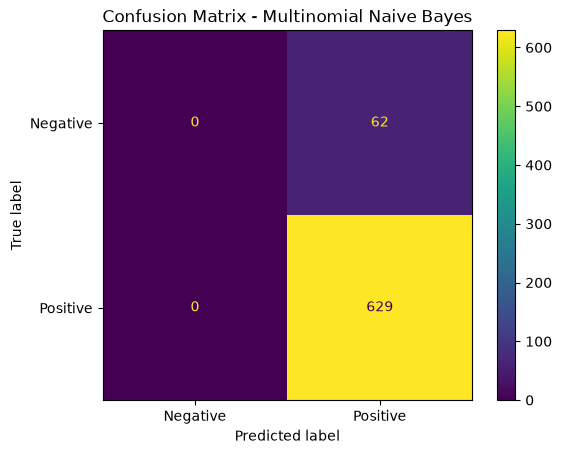

In [22]:
nb = MultinomialNB()

nb_result = evaluate_model(
    nb,
    X_train,
    X_test,
    y_train,
    y_test,
    'Multinomial Naive Bayes'
)

### Random Forest Classifier

Random Forest - Balanced
Accuracy : 0.9247
Precision: 0.9325
Recall   : 0.9889
F1 Score : 0.9599
Macro F1 : 0.6776

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.27      0.40        62
           1       0.93      0.99      0.96       629

    accuracy                           0.92       691
   macro avg       0.82      0.63      0.68       691
weighted avg       0.91      0.92      0.91       691



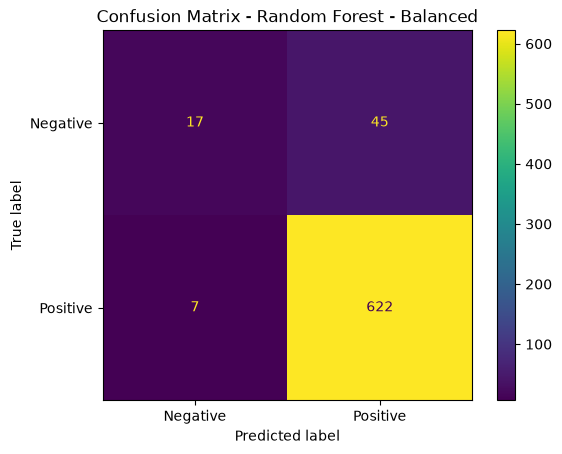

In [23]:
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=15,
    n_jobs=-1
)

rf_result = evaluate_model(
    rf,
    X_train,
    X_test,
    y_train,
    y_test,
    'Random Forest - Balanced'
)

### XGB Classifier

XGBoost
Accuracy : 0.9233
Precision: 0.9299
Recall   : 0.9905
F1 Score : 0.9592
Macro F1 : 0.6603

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.24      0.36        62
           1       0.93      0.99      0.96       629

    accuracy                           0.92       691
   macro avg       0.82      0.62      0.66       691
weighted avg       0.91      0.92      0.91       691



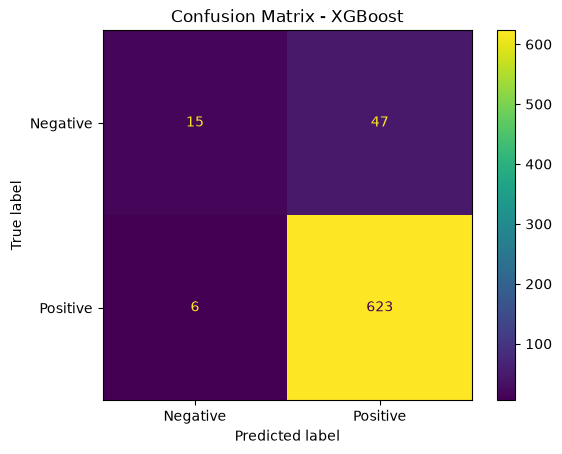

In [24]:
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=15
)

xgb_result = evaluate_model(
    xgb,
    X_train,
    X_test,
    y_train,
    y_test,
    'XGBoost'
)

### Comparing tree models performance

In [25]:
results = [
    lr_result,
    lr_balanced_result,
    svm_result,
    nb_result,
    rf_result,
    xgb_result
]

In [26]:
results_df = pd.DataFrame(results)

results_df = results_df.drop(
    columns=['Predictions']
)

results_df

,Model,Accuracy,Precision,Recall,F1,Macro F1
0,Logistic Regression,0.910275,0.910275,1.000000,0.953030,0.476515
1,Logistic Regression - Balanced,0.911722,0.958065,0.944356,0.951161,0.746257
2,Linear SVM - Balanced,0.930535,0.950388,0.974563,0.962323,0.758939
3,Multinomial Naive Bayes,0.910275,0.910275,1.000000,0.953030,0.476515
4,Random Forest - Balanced,0.924747,0.932534,0.988871,0.959877,0.677613
5,XGBoost,0.923300,0.929851,0.990461,0.959199,0.660323


In [ ]:
#remove me
results_df.sort_values(
    by='Macro F1',
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1,Macro F1
2,Linear SVM - Balanced,0.930535,0.950388,0.974563,0.962323,0.758939
1,Logistic Regression - Balanced,0.911722,0.958065,0.944356,0.951161,0.746257
4,Random Forest - Balanced,0.924747,0.932534,0.988871,0.959877,0.677613
5,XGBoost,0.923300,0.929851,0.990461,0.959199,0.660323
0,Logistic Regression,0.910275,0.910275,1.000000,0.953030,0.476515
3,Multinomial Naive Bayes,0.910275,0.910275,1.000000,0.953030,0.476515


In [28]:
negative_class_results = []

for result in results:
    
    pred = result['Predictions']
    
    negative_class_results.append({
        'Model': result['Model'],
        'Negative Precision': precision_score(
            y_test,
            pred,
            pos_label=0,
            zero_division=0
        ),
        'Negative Recall': recall_score(
            y_test,
            pred,
            pos_label=0,
            zero_division=0
        ),
        'Negative F1': f1_score(
            y_test,
            pred,
            pos_label=0,
            zero_division=0
        )
    })

negative_results_df = pd.DataFrame(
    negative_class_results
)

negative_results_df

,Model,Negative Precision,Negative Recall,Negative F1
0,Logistic Regression,0.000000,0.000000,0.000000
1,Logistic Regression - Balanced,0.507042,0.580645,0.541353
2,Linear SVM - Balanced,0.652174,0.483871,0.555556
3,Multinomial Naive Bayes,0.000000,0.000000,0.000000
4,Random Forest - Balanced,0.708333,0.274194,0.395349
5,XGBoost,0.714286,0.241935,0.361446


### LSTM

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping

Original dataset shape: (3150, 5)

Original target distribution:
feedback
1    2893
0     257
Name: count, dtype: int64

Original target percentages:
feedback
1    91.84127
0     8.15873
Name: proportion, dtype: float64

Dataset shape after removing duplicates:
(2301, 5)

Target distribution after removing duplicates:
feedback
1    2095
0     206
Name: count, dtype: int64

Data split:
Training: 1610
Validation: 345
Testing: 346

Training distribution:
feedback
1    1466
0     144
Name: count, dtype: int64

Validation distribution:
feedback
1    314
0     31
Name: count, dtype: int64

Test distribution:
feedback
1    315
0     31
Name: count, dtype: int64

Example original review:
"Overall love it. There are just some commands which aren't effective. It may be part user error or ""Alexa"" becoming accustom to what is being asked."

Example tokenized review:
[374, 12, 5, 116, 52, 38, 113, 288, 130, 1341, 1342, 5, 375, 39, 265, 416, 575, 47, 23, 1877, 1878, 4, 61, 9, 152, 446]

Padded sha

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 150, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,382,977 (5.28 MB)

 Trainable params: 1,382,977 (5.28 MB)

 Non-trainable params: 0 (0.00 B)


Starting LSTM training...

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 32s 190ms/step - accuracy: 0.7507 - loss: 0.5119 - val_accuracy: 0.9188 - val_loss: 0.2915
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 147ms/step - accuracy: 0.9748 - loss: 0.0840 - val_accuracy: 0.9333 - val_loss: 0.2535
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - accuracy: 0.9894 - loss: 0.0378 - val_accuracy: 0.9246 - val_loss: 0.3135
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 134ms/step - accuracy: 0.9959 - loss: 0.0125 - val_accuracy: 0.9333 - val_loss: 0.3488
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 121ms/step - accuracy: 0.9973 - loss: 0.0082 - val_accuracy: 0.9333 - val_loss: 0.3821


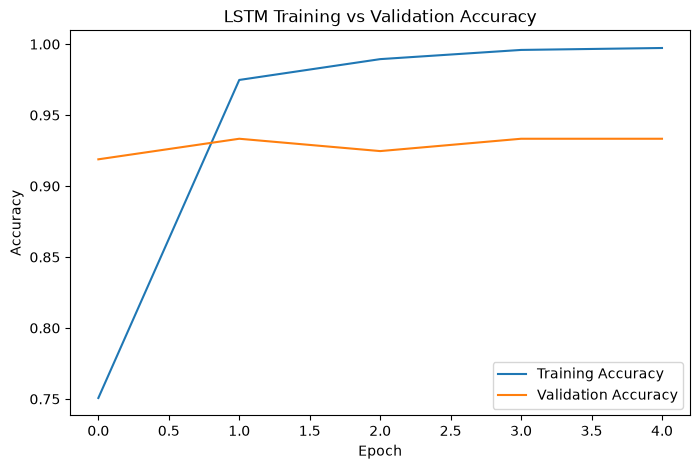

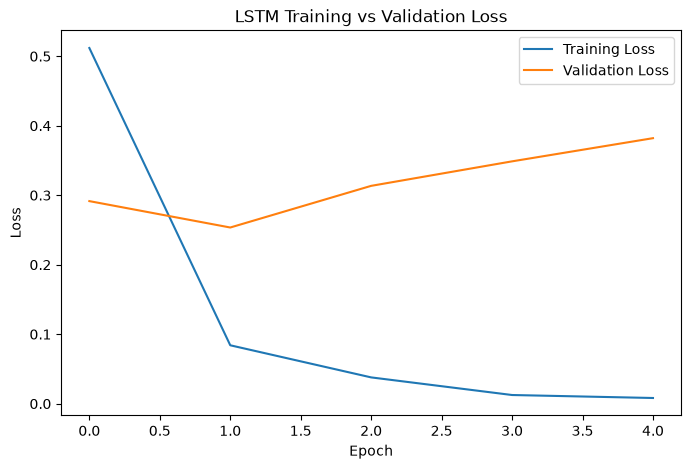


Validation performance at threshold 0.5:
              precision    recall  f1-score   support

    Negative       0.72      0.42      0.53        31
    Positive       0.94      0.98      0.96       314

    accuracy                           0.93       345
   macro avg       0.83      0.70      0.75       345
weighted avg       0.92      0.93      0.93       345


Threshold comparison:
    Threshold  Negative F1  Negative Recall  Macro F1
0        0.10     0.500000         0.354839  0.732972
1        0.15     0.488889         0.354839  0.726615
2        0.20     0.488889         0.354839  0.726615
3        0.25     0.521739         0.387097  0.743789
4        0.30     0.541667         0.419355  0.753699
5        0.35     0.541667         0.419355  0.753699
6        0.40     0.541667         0.419355  0.753699
7        0.45     0.530612         0.419355  0.747365
8        0.50     0.530612         0.419355  0.747365
9        0.55     0.549020         0.451613  0.756513
10       0.60 

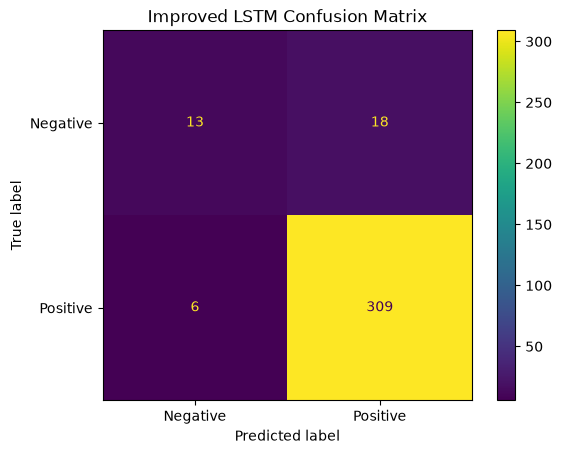


Negative Class Performance:
Negative Precision: 0.6842
Negative Recall   : 0.4194
Negative F1       : 0.5200


NEW REVIEW PREDICTIONS

Review:
I absolutely love this product. It works perfectly!
Positive probability: 0.9994
Predicted sentiment: Positive

Review:
This product is terrible and stopped working after two days.
Positive probability: 0.0012
Predicted sentiment: Negative


In [4]:
#Import libraries
from sklearn.utils import resample
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Dense,
    Dropout,
    Bidirectional
)

#prepare data

# Make sure missing reviews don't cause problems
X = data['verified_reviews'].fillna('').astype(str)

# Target 
y = data['feedback'].astype(int)

print("Original dataset shape:", data.shape)

print("\nOriginal target distribution:")
print(y.value_counts())

print("\nOriginal target percentages:")
print(y.value_counts(normalize=True) * 100)


# remove duplicate reviews 

model_data = data.drop_duplicates(
    subset='verified_reviews'
).copy()

X = model_data['verified_reviews'].fillna('').astype(str)
y = model_data['feedback'].astype(int)

print("\nDataset shape after removing duplicates:")
print(model_data.shape)

print("\nTarget distribution after removing duplicates:")
print(y.value_counts())


# train/validation/test split

# first split:
# 70% training
# 30% temporary data

X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=15,
    stratify=y
)


# second split:
# temporary data is divided equally:
# 15% validation
# 15% test

X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text,
    y_temp,
    test_size=0.50,
    random_state=15,
    stratify=y_temp
)


print("\nData split:")
print("Training:", len(X_train_text))
print("Validation:", len(X_val_text))
print("Testing:", len(X_test_text))


print("\nTraining distribution:")
print(y_train.value_counts())

print("\nValidation distribution:")
print(y_val.value_counts())

print("\nTest distribution:")
print(y_test.value_counts())


# tokenization

# Maximum vocabulary size
max_words = 10000

tokenizer = Tokenizer(
    num_words=max_words,
    oov_token="<OOV>"
)

# Fit tokenizer ONLY on training data
tokenizer.fit_on_texts(X_train_text)


# Convert text to integer sequences
X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_val_seq = tokenizer.texts_to_sequences(X_val_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)


print("\nExample original review:")
print(X_train_text.iloc[0])

print("\nExample tokenized review:")
print(X_train_seq[0])


# padding

max_len = 150

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_len,
    padding='post',
    truncating='post'
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=max_len,
    padding='post',
    truncating='post'
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_len,
    padding='post',
    truncating='post'
)


print("\nPadded shapes:")
print("Training:", X_train_pad.shape)
print("Validation:", X_val_pad.shape)
print("Testing:", X_test_pad.shape)


# oversample minority class 

# create a temporary DataFrame containing 
# training text and target 

train_df = pd.DataFrame({
    'text': X_train_text.values,
    'target': y_train.values
})


# separate positive and negative reviews

negative = train_df[train_df['target'] == 0]
positive = train_df[train_df['target'] == 1]


print("\nBefore oversampling:")
print(train_df['target'].value_counts())


#oversample negative class
negative_oversampled = resample(
    negative,
    replace=True,
    n_samples=len(positive),
    random_state=15
)


#combine positive and oversampled negative reviews

balanced_train = pd.concat(
    [positive, negative_oversampled]
)


#shuffle

balanced_train = balanced_train.sample(
    frac=1,
    random_state=15
).reset_index(drop=True)


print("\nAfter oversampling:")
print(balanced_train['target'].value_counts())


# tokenize balanced training data

X_train_balanced_seq = tokenizer.texts_to_sequences(
    balanced_train['text']
)


# pad balanced training sequences

X_train_balanced_pad = pad_sequences(
    X_train_balanced_seq,
    maxlen=max_len,
    padding='post',
    truncating='post'
)


# balanced target

y_train_balanced = balanced_train['target'].values


print("\nBalanced training shape:")
print(X_train_balanced_pad.shape)

print("\nBalanced target shape:")
print(y_train_balanced.shape)


# build bidirectional lstm model

model = Sequential([
    
    # input sequence
    Input(shape=(max_len,)),
    
    # word embeddings
    Embedding(
        input_dim=max_words,
        output_dim=128
    ),
    
    # bidirectional LSTM
    Bidirectional(
        LSTM(64)
    ),
    
    # prevent overfitting
    Dropout(0.5),
    
    # fully connected layer
    Dense(
        32,
        activation='relu'
    ),
    
    # more regularization
    Dropout(0.3),
    
    # binary classification
    Dense(
        1,
        activation='sigmoid'
    )
])


# complete model

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


# display model architecture

print("\nModel architecture:")
model.summary()


# early stopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)


# train model

print("\nStarting LSTM training...\n")

history = model.fit(
    X_train_balanced_pad,
    y_train_balanced,
    
    # Use original validation set
    validation_data=(
        X_val_pad,
        y_val
    ),
    
    epochs=15,
    batch_size=32,
    
    callbacks=[
        early_stopping
    ],
    
    verbose=1
)


# plot training/validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.title(
    'LSTM Training vs Validation Accuracy'
)

plt.legend()

plt.show()


# plot training/validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.title(
    'LSTM Training vs Validation Loss'
)

plt.legend()

plt.show()


# validation predictions

val_prob = model.predict(
    X_val_pad,
    verbose=0
).ravel()


# default threshold = 0.5

val_pred = (
    val_prob >= 0.5
).astype(int)


print("\nValidation performance at threshold 0.5:")

print(
    classification_report(
        y_val,
        val_pred,
        target_names=[
            'Negative',
            'Positive'
        ],
        zero_division=0
    )
)


# find best classification threshold

thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

threshold_results = []


for threshold in thresholds:
    
    predictions = (
        val_prob >= threshold
    ).astype(int)
    
    
    # F1 for negative class
    negative_f1 = f1_score(
        y_val,
        predictions,
        pos_label=0,
        zero_division=0
    )
    
    
    # Macro F1
    macro_f1 = f1_score(
        y_val,
        predictions,
        average='macro',
        zero_division=0
    )
    
    
    # Negative recall
    negative_recall = recall_score(
        y_val,
        predictions,
        pos_label=0,
        zero_division=0
    )
    
    
    threshold_results.append({
        'Threshold': threshold,
        'Negative F1': negative_f1,
        'Negative Recall': negative_recall,
        'Macro F1': macro_f1
    })


# Convert results to DataFrame

threshold_df = pd.DataFrame(
    threshold_results
)


print("\nThreshold comparison:")
print(threshold_df)


#select best threshold

best_threshold = threshold_df.loc[
    threshold_df['Macro F1'].idxmax(),
    'Threshold'
]


print(
    "\nBest threshold based on Macro F1:",
    best_threshold
)


# final test predictions

test_prob = model.predict(
    X_test_pad,
    verbose=0
).ravel()


# Use the threshold selected using validation data

test_pred = (
    test_prob >= best_threshold
).astype(int)


# final model evaluation

accuracy = accuracy_score(
    y_test,
    test_pred
)

precision = precision_score(
    y_test,
    test_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    test_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    test_pred,
    zero_division=0
)

macro_f1 = f1_score(
    y_test,
    test_pred,
    average='macro',
    zero_division=0
)


print("\n")
print("=" * 60)
print("FINAL LSTM TEST RESULTS")
print("=" * 60)

print(
    f"Accuracy : {accuracy:.4f}"
)

print(
    f"Precision: {precision:.4f}"
)

print(
    f"Recall   : {recall:.4f}"
)

print(
    f"F1 Score : {f1:.4f}"
)

print(
    f"Macro F1 : {macro_f1:.4f}"
)


# classification report

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        test_pred,
        target_names=[
            'Negative',
            'Positive'
        ],
        zero_division=0
    )
)


# confusion matrix

cm = confusion_matrix(
    y_test,
    test_pred
)


print("\nConfusion Matrix:")
print(cm)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        'Negative',
        'Positive'
    ]
)

disp.plot()

plt.title(
    'Improved LSTM Confusion Matrix'
)

plt.show()


# negative class performance

negative_precision = precision_score(
    y_test,
    test_pred,
    pos_label=0,
    zero_division=0
)

negative_recall = recall_score(
    y_test,
    test_pred,
    pos_label=0,
    zero_division=0
)

negative_f1 = f1_score(
    y_test,
    test_pred,
    pos_label=0,
    zero_division=0
)


print("\nNegative Class Performance:")
print(
    f"Negative Precision: {negative_precision:.4f}"
)

print(
    f"Negative Recall   : {negative_recall:.4f}"
)

print(
    f"Negative F1       : {negative_f1:.4f}"
)


# testing a new review

new_reviews = [
    "I absolutely love this product. It works perfectly!",
    "This product is terrible and stopped working after two days."
]


# convert new reviews into sequences

new_sequences = tokenizer.texts_to_sequences(
    new_reviews
)


# Pad them

new_padded = pad_sequences(
    new_sequences,
    maxlen=max_len,
    padding='post',
    truncating='post'
)


# Predict probabilities

new_probabilities = model.predict(
    new_padded,
    verbose=0
).ravel()


# Apply our selected threshold

new_predictions = (
    new_probabilities >= best_threshold
).astype(int)


# Display predictions

print("\n")
print("=" * 60)
print("NEW REVIEW PREDICTIONS")
print("=" * 60)


for review, probability, prediction in zip(
    new_reviews,
    new_probabilities,
    new_predictions
):
    
    sentiment = (
        "Positive"
        if prediction == 1
        else "Negative"
    )
    
    
    print("\nReview:")
    print(review)
    
    print(
        "Positive probability:",
        round(float(probability), 4)
    )
    
    print(
        "Predicted sentiment:",
        sentiment
    )


In [ ]:
# stratified k-fold cross-validation for lstm
# hyperparameter training

from sklearn.model_selection import StratifiedKFold


import tensorflow as tf


hyperparameter_configs = [

    {
        'embedding_dim': 64,
        'lstm_units': 32,
        'dropout': 0.3,
        'max_len': 100
    },

    {
        'embedding_dim': 128,
        'lstm_units': 64,
        'dropout': 0.5,
        'max_len': 150
    },

    {
        'embedding_dim': 128,
        'lstm_units': 128,
        'dropout': 0.5,
        'max_len': 150
    },

    {
        'embedding_dim': 256,
        'lstm_units': 64,
        'dropout': 0.3,
        'max_len': 200
    },

    {
        'embedding_dim': 128,
        'lstm_units': 64,
        'dropout': 0.3,
        'max_len': 200
    }
]


# stratified k-fold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=15
)


# function to create LSTM

def create_lstm(
    max_words,
    max_len,
    embedding_dim,
    lstm_units,
    dropout
):

    model = Sequential([

        Input(shape=(max_len,)),

        Embedding(
            input_dim=max_words,
            output_dim=embedding_dim
        ),

        Bidirectional(
            LSTM(lstm_units)
        ),

        Dropout(dropout),

        Dense(
            32,
            activation='relu'
        ),

        Dropout(0.3),

        Dense(
            1,
            activation='sigmoid'
        )
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model


# Run cross-validation

all_results = []


for config_number, config in enumerate(
    hyperparameter_configs,
    start=1
):

    print("\n")
    print("=" * 70)
    print(
        f"CONFIGURATION {config_number}"
    )
    print("=" * 70)

    print(config)


    fold_scores = []


    # each fold
    
    for fold, (train_idx, val_idx) in enumerate(
        skf.split(X, y),
        start=1
    ):

        print(
            f"\nTraining Fold {fold}/5..."
        )

        # split text and labels

        X_train_text = X.iloc[
            train_idx
        ]

        X_val_text = X.iloc[
            val_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]


        # tokenizer

        max_words = 10000

        tokenizer = Tokenizer(
            num_words=max_words,
            oov_token="<OOV>"
        )

        # fit only on training fold
        tokenizer.fit_on_texts(
            X_train_text
        )


        # convert training text
        X_train_seq = tokenizer.texts_to_sequences(
            X_train_text
        )

        # convert validation text
        X_val_seq = tokenizer.texts_to_sequences(
            X_val_text
        )


        # padding 
        
        X_train_pad = pad_sequences(
            X_train_seq,
            maxlen=config['max_len'],
            padding='post',
            truncating='post'
        )

        X_val_pad = pad_sequences(
            X_val_seq,
            maxlen=config['max_len'],
            padding='post',
            truncating='post'
        )

        # Oversample minority class   

        train_df = pd.DataFrame({
            'text': X_train_text.values,
            'target': y_train.values
        })


        negative = train_df[
            train_df['target'] == 0
        ]

        positive = train_df[
            train_df['target'] == 1
        ]


        negative_oversampled = resample(
            negative,
            replace=True,
            n_samples=len(positive),
            random_state=15
        )


        balanced_train = pd.concat([
            positive,
            negative_oversampled
        ])


        balanced_train = balanced_train.sample(
            frac=1,
            random_state=15
        ).reset_index(drop=True)

        # convert balanced training text to sequences
       
        X_train_balanced_seq = tokenizer.texts_to_sequences(
            balanced_train['text']
        )


        X_train_balanced_pad = pad_sequences(
            X_train_balanced_seq,
            maxlen=config['max_len'],
            padding='post',
            truncating='post'
        )


        y_train_balanced = (
            balanced_train['target'].values
        )

        # create fresh LSTM

        model = create_lstm(
            max_words=max_words,
            max_len=config['max_len'],
            embedding_dim=config['embedding_dim'],
            lstm_units=config['lstm_units'],
            dropout=config['dropout']
        )

        # early stopping

        early_stopping = EarlyStopping(
            monitor='val_loss',
            patience=2,
            restore_best_weights=True
        )


        # train

        model.fit(
            X_train_balanced_pad,
            y_train_balanced,

            validation_data=(
                X_val_pad,
                y_val
            ),

            epochs=10,
            batch_size=32,

            callbacks=[
                early_stopping
            ],

            verbose=0
        )

        # Validation predictions

        y_prob = model.predict(
            X_val_pad,
            verbose=0
        ).ravel()


        # Default threshold
        y_pred = (
            y_prob >= 0.5
        ).astype(int)

        # Calculate metrics

        accuracy = accuracy_score(
            y_val,
            y_pred
        )

        precision = precision_score(
            y_val,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_val,
            y_pred,
            zero_division=0
        )

        macro_f1 = f1_score(
            y_val,
            y_pred,
            average='macro',
            zero_division=0
        )

        negative_f1 = f1_score(
            y_val,
            y_pred,
            pos_label=0,
            zero_division=0
        )

        negative_recall = recall_score(
            y_val,
            y_pred,
            pos_label=0,
            zero_division=0
        )

        # save fold results
     

        fold_scores.append({

            'Fold': fold,

            'Accuracy': accuracy,

            'Precision': precision,

            'Recall': recall,

            'Macro F1': macro_f1,

            'Negative F1': negative_f1,

            'Negative Recall': negative_recall

        })


        print(
            f"Fold {fold} | "
            f"Macro F1: {macro_f1:.4f} | "
            f"Negative F1: {negative_f1:.4f}"
        )


        # Clear TensorFlow model
        tf.keras.backend.clear_session()


    # average results over folds
  

    fold_df = pd.DataFrame(
        fold_scores
    )


    mean_results = {

        'Embedding': config['embedding_dim'],

        'LSTM Units': config['lstm_units'],

        'Dropout': config['dropout'],

        'Max Length': config['max_len'],

        'Mean Accuracy':
            fold_df['Accuracy'].mean(),

        'Mean Precision':
            fold_df['Precision'].mean(),

        'Mean Recall':
            fold_df['Recall'].mean(),

        'Mean Macro F1':
            fold_df['Macro F1'].mean(),

        'Mean Negative F1':
            fold_df['Negative F1'].mean(),

        'Mean Negative Recall':
            fold_df['Negative Recall'].mean(),

        'Std Macro F1':
            fold_df['Macro F1'].std()

    }


    all_results.append(
        mean_results
    )


# compare hyperparameters

results_df = pd.DataFrame(
    all_results
)


results_df = results_df.sort_values(
    by='Mean Macro F1',
    ascending=False
)


print("\n")
print("=" * 70)
print("HYPERPARAMETER TUNING RESULTS")
print("=" * 70)

print(
    results_df.to_string(
        index=False
    )
)


# best configuration

best_config = results_df.iloc[0]


print("\n")
print("=" * 70)
print("BEST CONFIGURATION")
print("=" * 70)

print(
    best_config
)

Dataset shape: (2301, 5)

Class distribution:
feedback
1    2095
0     206
Name: count, dtype: int64


CONFIGURATION 1
{'embedding_dim': 64, 'lstm_units': 32, 'dropout': 0.3, 'max_len': 100}

Training Fold 1/5...
Fold 1 | Macro F1: 0.7948 | Negative F1: 0.6279


Training Fold 2/5...
Fold 2 | Macro F1: 0.7020 | Negative F1: 0.4578

Training Fold 3/5...
Fold 3 | Macro F1: 0.7145 | Negative F1: 0.4898

Training Fold 4/5...
Fold 4 | Macro F1: 0.7378 | Negative F1: 0.5195

Training Fold 5/5...
Fold 5 | Macro F1: 0.6945 | Negative F1: 0.4348


CONFIGURATION 2
{'embedding_dim': 128, 'lstm_units': 64, 'dropout': 0.5, 'max_len': 150}

Training Fold 1/5...
Fold 1 | Macro F1: 0.7716 | Negative F1: 0.5823

Training Fold 2/5...
Fold 2 | Macro F1: 0.7378 | Negative F1: 0.5275

Training Fold 3/5...
Fold 3 | Macro F1: 0.6836 | Negative F1: 0.4167

Training Fold 4/5...
Fold 4 | Macro F1: 0.7414 | Negative F1: 0.5333

Training Fold 5/5...
Fold 5 | Macro F1: 0.6927 | Negative F1: 0.4262


CONFIGURATION 3

Dataset shape: (2301, 5)

Class distribution:
feedback
1    2095
0     206
Name: count, dtype: int64

Development set: 1955
Test set: 346

Development distribution:
feedback
1    1780
0     175
Name: count, dtype: int64

Test distribution:
feedback
1    315
0     31
Name: count, dtype: int64

Training: 1609
Validation: 346
Test: 346

Padded shapes:
Training: (1609, 100)
Validation: (346, 100)
Test: (346, 100)

Before oversampling:
target
1    1465
0     144
Name: count, dtype: int64

After oversampling:
target
1    1465
0    1465
Name: count, dtype: int64


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 100, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 666,945 (2.54 MB)

 Trainable params: 666,945 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 59ms/step - accuracy: 0.7096 - loss: 0.5511 - val_accuracy: 0.8844 - val_loss: 0.3135
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.9635 - loss: 0.1147 - val_accuracy: 0.9220 - val_loss: 0.3480
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.9949 - loss: 0.0230 - val_accuracy: 0.8988 - val_loss: 0.4666
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.9986 - loss: 0.0084 - val_accuracy: 0.9046 - val_loss: 0.5714

Validation Results:
              precision    recall  f1-score   support

    Negative       0.36      0.39      0.38        31
    Positive       0.94      0.93      0.94       315

    accuracy                           0.88       346
   macro avg       0.65      0.66      0.66       346
weighted avg       0.89      0.88      0.89       346


Best validation threshold: 0.3500000000000001


FINAL LSTM TEST RESULTS
Accuracy : 0.9306
Precision: 0.9533
Recall   : 0.9714
F1 Score : 0.962

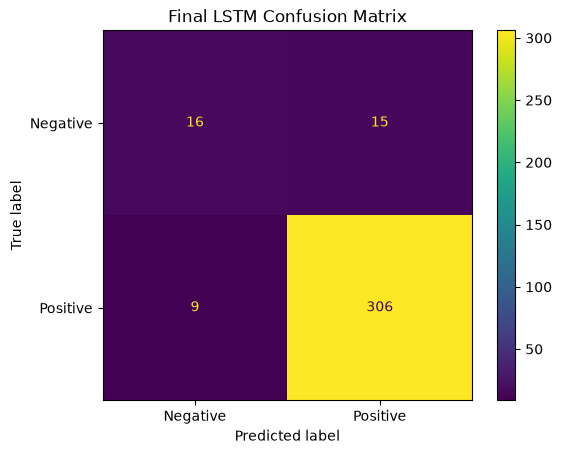

In [5]:
# Final LSTM model using best hyperparameters

# prepare data

model_data = data.drop_duplicates(
    subset='verified_reviews'
).copy()

X = model_data['verified_reviews'].fillna('').astype(str)
y = model_data['feedback'].astype(int)

print("Dataset shape:", model_data.shape)

print("\nClass distribution:")
print(y.value_counts())


# create final test set

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=15,
    stratify=y
)

print("\nDevelopment set:", len(X_dev))
print("Test set:", len(X_test))

print("\nDevelopment distribution:")
print(y_dev.value_counts())

print("\nTest distribution:")
print(y_test.value_counts())


# best hyperparameters from cross validation

max_words = 10000

max_len = 100

embedding_dim = 64

lstm_units = 32

dropout = 0.3


# create train/validation set

X_train_text, X_val_text, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.1765,
    random_state=15,
    stratify=y_dev
)

# This gives approximately:

# 70% total training
# 15% validation
# 15% test


print("\nTraining:", len(X_train_text))
print("Validation:", len(X_val_text))
print("Test:", len(X_test))

#tokenizer

tokenizer = Tokenizer(
    num_words=max_words,
    oov_token="<OOV>"
)

# Fit only on training data
tokenizer.fit_on_texts(
    X_train_text
)


#convert text to sequences

X_train_seq = tokenizer.texts_to_sequences(
    X_train_text
)

X_val_seq = tokenizer.texts_to_sequences(
    X_val_text
)

X_test_seq = tokenizer.texts_to_sequences(
    X_test
)


# padding

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_len,
    padding='post',
    truncating='post'
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=max_len,
    padding='post',
    truncating='post'
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_len,
    padding='post',
    truncating='post'
)


print("\nPadded shapes:")
print("Training:", X_train_pad.shape)
print("Validation:", X_val_pad.shape)
print("Test:", X_test_pad.shape)


# oversample negative class

train_df = pd.DataFrame({
    'text': X_train_text.values,
    'target': y_train.values
})

negative = train_df[
    train_df['target'] == 0
]

positive = train_df[
    train_df['target'] == 1
]

print("\nBefore oversampling:")
print(train_df['target'].value_counts())


negative_oversampled = resample(
    negative,
    replace=True,
    n_samples=len(positive),
    random_state=15
)


balanced_train = pd.concat([
    positive,
    negative_oversampled
])


balanced_train = balanced_train.sample(
    frac=1,
    random_state=15
).reset_index(drop=True)


print("\nAfter oversampling:")
print(balanced_train['target'].value_counts())


# prepare balanced training sequences

X_train_balanced_seq = tokenizer.texts_to_sequences(
    balanced_train['text']
)

X_train_balanced_pad = pad_sequences(
    X_train_balanced_seq,
    maxlen=max_len,
    padding='post',
    truncating='post'
)

y_train_balanced = balanced_train['target'].values


# build final lstm
model = Sequential([

    Input(shape=(max_len,)),

    Embedding(
        input_dim=max_words,
        output_dim=embedding_dim
    ),

    Bidirectional(
        LSTM(lstm_units)
    ),

    Dropout(dropout),

    Dense(
        32,
        activation='relu'
    ),

    Dropout(0.3),

    Dense(
        1,
        activation='sigmoid'
    )
])


# compile
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


model.summary()


# early stopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)


# train final LSTM

history = model.fit(
    X_train_balanced_pad,
    y_train_balanced,

    validation_data=(
        X_val_pad,
        y_val
    ),

    epochs=15,
    batch_size=32,

    callbacks=[
        early_stopping
    ],

    verbose=1
)


# validation predictions
val_prob = model.predict(
    X_val_pad,
    verbose=0
).ravel()


val_pred = (
    val_prob >= 0.5
).astype(int)


print("\nValidation Results:")
print(
    classification_report(
        y_val,
        val_pred,
        target_names=[
            'Negative',
            'Positive'
        ],
        zero_division=0
    )
)


# find best threshold using validation set

thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

threshold_results = []


for threshold in thresholds:

    predictions = (
        val_prob >= threshold
    ).astype(int)

    macro_f1 = f1_score(
        y_val,
        predictions,
        average='macro',
        zero_division=0
    )

    negative_f1 = f1_score(
        y_val,
        predictions,
        pos_label=0,
        zero_division=0
    )

    threshold_results.append({
        'Threshold': threshold,
        'Macro F1': macro_f1,
        'Negative F1': negative_f1
    })


threshold_df = pd.DataFrame(
    threshold_results
)


best_threshold = threshold_df.loc[
    threshold_df['Macro F1'].idxmax(),
    'Threshold'
]


print(
    "\nBest validation threshold:",
    best_threshold
)


# final test prediction

test_prob = model.predict(
    X_test_pad,
    verbose=0
).ravel()


test_pred = (
    test_prob >= best_threshold
).astype(int)


# final test results

accuracy = accuracy_score(
    y_test,
    test_pred
)

precision = precision_score(
    y_test,
    test_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    test_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    test_pred,
    zero_division=0
)

macro_f1 = f1_score(
    y_test,
    test_pred,
    average='macro',
    zero_division=0
)


print("\n")
print("=" * 60)
print("FINAL LSTM TEST RESULTS")
print("=" * 60)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"Macro F1 : {macro_f1:.4f}")


# classification report 

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        test_pred,
        target_names=[
            'Negative',
            'Positive'
        ],
        zero_division=0
    )
)


# confusion matrix

cm = confusion_matrix(
    y_test,
    test_pred
)

print("\nConfusion Matrix:")
print(cm)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        'Negative',
        'Positive'
    ]
)

disp.plot()

plt.title(
    'Final LSTM Confusion Matrix'
)

plt.show()


### CNN + BiLSTM

DATA SPLIT
Training   : 1609
Validation : 346
Test       : 346

Original training distribution 
Positive: 1465
Negative: 144

Oversampled training distribution 
target
1    1465
0    1465
Name: count, dtype: int64

CNN + BiLSTM MODEL


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_4         │ (None, 100, 64)   │    640,000 │ input_layer_4[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_2 │ (None, 100, 64)   │          0 │ embedding_4[0][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 100, 64)   │      8,256 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 100, 64)   │     12,352 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ conv1d_4[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ conv1d_5[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 128)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_4     │ (None, 64)        │     24,832 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 128)       │          0 │ concatenate_4[0]… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 64)        │          0 │ bidirectional_4[… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_5       │ (None, 192)       │          0 │ dropout_10[0][0], │
│ (Concatenate)       │                   │            │ dropout_11[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 32)        │      6,176 │ concatenate_5[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 32)        │          0 │ dense_8[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 1)         │         33 │ dropout_12[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 691,649 (2.64 MB)

 Trainable params: 691,649 (2.64 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 23s 123ms/step - accuracy: 0.5952 - loss: 0.6792 - val_accuracy: 0.5838 - val_loss: 0.6640 - learning_rate: 3.0000e-04
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - accuracy: 0.7130 - loss: 0.6027 - val_accuracy: 0.7370 - val_loss: 0.5305 - learning_rate: 3.0000e-04
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - accuracy: 0.8143 - loss: 0.4556 - val_accuracy: 0.8584 - val_loss: 0.3517 - learning_rate: 3.0000e-04
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - accuracy: 0.9191 - loss: 0.2666 - val_accuracy: 0.9017 - val_loss: 0.2412 - learning_rate: 3.0000e-04
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - accuracy: 0.9696 - loss: 0.1239 - val_accuracy: 0.9277 - val_loss: 0.2025 - learning_rate: 3.0000e-04
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.9829 - loss: 0.0725
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 106ms/step - accuracy:

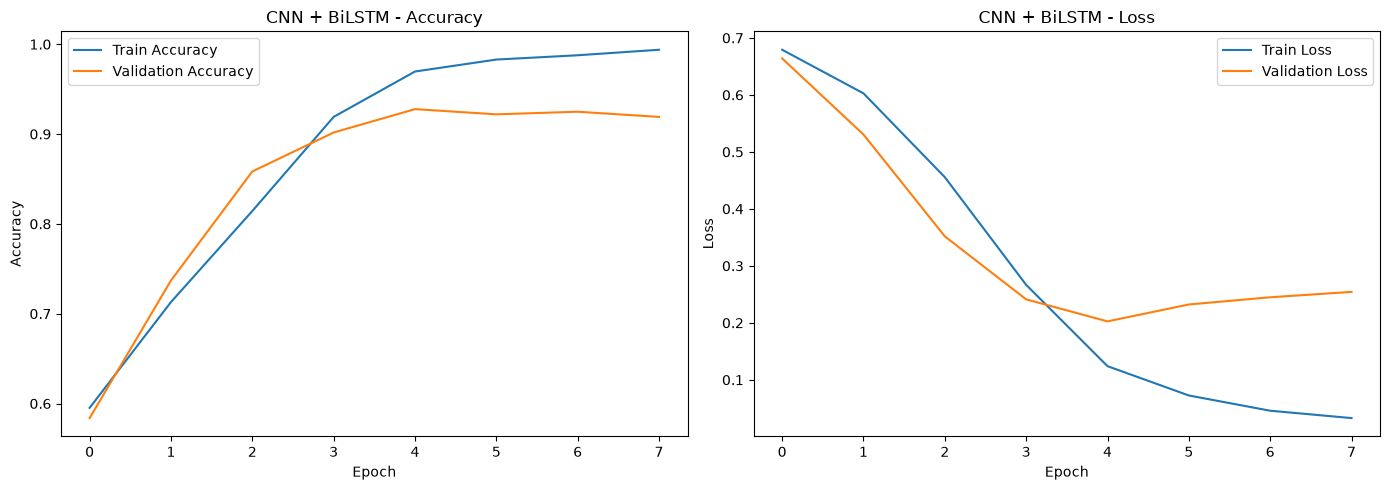


VALIDATION RESULTS @ THRESHOLD 0.50
              precision    recall  f1-score   support

    Negative       0.64      0.45      0.53        31
    Positive       0.95      0.97      0.96       315

    accuracy                           0.93       346
   macro avg       0.79      0.71      0.74       346
weighted avg       0.92      0.93      0.92       346


THRESHOLD TUNING
 Threshold  Macro F1  Negative F1  Negative Recall
      0.10  0.536027     0.117647         0.064516
      0.15  0.601994     0.250000         0.161290
      0.20  0.665245     0.372093         0.258065
      0.25  0.702902     0.444444         0.322581
      0.30  0.702902     0.444444         0.322581
      0.35  0.737490     0.510638         0.387097
      0.40  0.750481     0.538462         0.451613
      0.45  0.744589     0.528302         0.451613
      0.50  0.744589     0.528302         0.451613
      0.55  0.731330     0.508475         0.483871
      0.60  0.724522     0.500000         0.516129
      

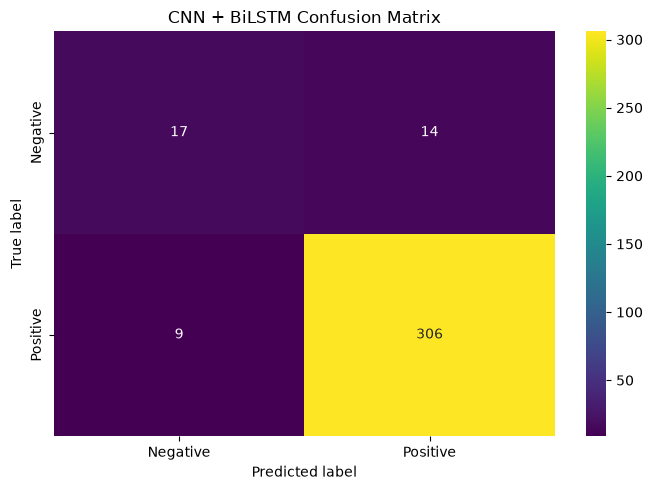


MODEL COMPARISON
                       Model  Accuracy  Macro F1  Negative F1  Negative Recall
Previous Oversampling BiLSTM  0.922000  0.749900     0.540000         0.520000
                CNN + BiLSTM  0.933526  0.780135     0.596491         0.548387


NameError: name 'SAVE_MODEL' is not defined

In [ ]:
from tensorflow.keras.models import Model
import tensorflow as tf
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SpatialDropout1D,
    Conv1D,
    GlobalMaxPooling1D,
    Bidirectional,
    LSTM,
    Dropout,
    Dense,
    Concatenate
)

from tensorflow.keras.callbacks import ReduceLROnPlateau

# rerproducibility

SEED = 15

np.random.seed(SEED)
tf.random.set_seed(SEED)

# train/validation/test split

X_train_dev, X_test, y_train_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=SEED,
    stratify=y
)

X_train_text, X_val_text, y_train, y_val = train_test_split(
    X_train_dev,
    y_train_dev,
    test_size=0.1765,
    random_state=SEED,
    stratify=y_train_dev
)

print("DATA SPLIT")

print("Training   :", len(X_train_text))
print("Validation :", len(X_val_text))
print("Test       :", len(X_test))


# tokenization
# We intentionally use raw reviews.
# No stemming/stopword removal.

max_words = 10000
max_len = 100

tokenizer = Tokenizer(
    num_words=max_words,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train_text)


# text -> sequences

X_train_seq = tokenizer.texts_to_sequences(
    X_train_text
)

X_val_seq = tokenizer.texts_to_sequences(
    X_val_text
)

X_test_seq = tokenizer.texts_to_sequences(
    X_test
)


# padding

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)


# oversampling

train_df = pd.DataFrame({
    "text": X_train_text.values,
    "target": y_train.values
})

positive = train_df[
    train_df["target"] == 1
]

negative = train_df[
    train_df["target"] == 0
]

print("\n" + "=" * 70)
print("Original training distribution ")
print("=" * 70)

print("Positive:", len(positive))
print("Negative:", len(negative))


# Oversample negative class to match positive class
negative_oversampled = resample(
    negative,
    replace=True,
    n_samples=len(positive),
    random_state=SEED
)

balanced_train = pd.concat([
    positive,
    negative_oversampled
])

balanced_train = balanced_train.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)


print("\n" + "=" * 70)
print("Oversampled training distribution ")
print("=" * 70)

print(
    balanced_train["target"].value_counts()
)


# convert oversampled text to sequences
X_balanced_seq = tokenizer.texts_to_sequences(
    balanced_train["text"]
)

X_balanced_pad = pad_sequences(
    X_balanced_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

y_balanced = balanced_train["target"].values


# Build CNN+BiLSTM
# Two branches:
# Branch 1:
# CNN -> GlobalMaxPooling
# Detects short/local sentiment phrases.
# Branch 2:
# BiLSTM
# Captures sequence/context.
# Then:
# Concatenate both representations


embedding_dim = 64


# Input
inputs = Input(
    shape=(max_len,)
)


# shared embedding

embedding = Embedding(
    input_dim=max_words,
    output_dim=embedding_dim
)(inputs)


# Slight regularization
embedding = SpatialDropout1D(
    0.20
)(embedding)


# CNN Branch
# Kernel size 2 captures short 2-word patterns.
# Kernel size 3 captures 3-word patterns.


conv_2 = Conv1D(
    filters=64,
    kernel_size=2,
    activation="relu",
    padding="same"
)(embedding)

pool_2 = GlobalMaxPooling1D()(
    conv_2
)


conv_3 = Conv1D(
    filters=64,
    kernel_size=3,
    activation="relu",
    padding="same"
)(embedding)

pool_3 = GlobalMaxPooling1D()(
    conv_3
)


# Combine CNN features
cnn_features = Concatenate()([
    pool_2,
    pool_3
])


cnn_features = Dropout(
    0.35
)(cnn_features)


# BiLSTM branch

lstm_features = Bidirectional(
    LSTM(
        32,
        dropout=0.20,
        recurrent_dropout=0.20
    )
)(embedding)


lstm_features = Dropout(
    0.35
)(lstm_features)


# Combine CNN + BiLSTM


combined = Concatenate()([
    cnn_features,
    lstm_features
])


# fInal classifier

combined = Dense(
    32,
    activation="relu"
)(combined)

combined = Dropout(
    0.30
)(combined)


outputs = Dense(
    1,
    activation="sigmoid"
)(combined)


# Create model
model_cnn_lstm = Model(
    inputs=inputs,
    outputs=outputs
)


# compile

optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0003
)

model_cnn_lstm.compile(
    optimizer=optimizer,
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


print("\n" + "=" * 70)
print("CNN + BiLSTM MODEL")
print("=" * 70)

model_cnn_lstm.summary()


# callbacks
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-6,
    verbose=1
)


# train

history = model_cnn_lstm.fit(
    X_balanced_pad,
    y_balanced,
    validation_data=(
        X_val_pad,
        y_val
    ),
    epochs=20,
    batch_size=32,
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    verbose=1
)


# training curves

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


# Accuracy
axes[0].plot(
    history.history["accuracy"],
    label="Train Accuracy"
)

axes[0].plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title(
    "CNN + BiLSTM - Accuracy"
)

axes[0].set_xlabel(
    "Epoch"
)

axes[0].set_ylabel(
    "Accuracy"
)

axes[0].legend()


# Loss
axes[1].plot(
    history.history["loss"],
    label="Train Loss"
)

axes[1].plot(
    history.history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title(
    "CNN + BiLSTM - Loss"
)

axes[1].set_xlabel(
    "Epoch"
)

axes[1].set_ylabel(
    "Loss"
)

axes[1].legend()


plt.tight_layout()
plt.show()


# validation predictions

val_prob = model_cnn_lstm.predict(
    X_val_pad,
    verbose=0
).ravel()


# validation @ default threshold


val_pred_05 = (
    val_prob >= 0.50
).astype(int)


print("\n" + "=" * 70)
print("VALIDATION RESULTS @ THRESHOLD 0.50")
print("=" * 70)

print(
    classification_report(
        y_val,
        val_pred_05,
        target_names=[
            "Negative",
            "Positive"
        ],
        zero_division=0
    )
)


# Threshold tuning
# Optimize Macro F1

threshold_results = []


for threshold in np.arange(
    0.10,
    0.91,
    0.05
):

    val_pred = (
        val_prob >= threshold
    ).astype(int)


    macro_f1 = f1_score(
        y_val,
        val_pred,
        average="macro"
    )


    negative_f1 = f1_score(
        y_val,
        val_pred,
        pos_label=0,
        zero_division=0
    )


    negative_recall = recall_score(
        y_val,
        val_pred,
        pos_label=0,
        zero_division=0
    )


    threshold_results.append({
        "Threshold": round(
            threshold,
            2
        ),
        "Macro F1": macro_f1,
        "Negative F1": negative_f1,
        "Negative Recall": negative_recall
    })


threshold_df = pd.DataFrame(
    threshold_results
)


print("\n" + "=" * 70)
print("THRESHOLD TUNING")
print("=" * 70)

print(
    threshold_df.to_string(
        index=False
    )
)


# Best threshold based on Macro F1
best_row = threshold_df.loc[
    threshold_df["Macro F1"].idxmax()
]

best_threshold = float(
    best_row["Threshold"]
)


print(
    f"\nBest validation threshold: "
    f"{best_threshold:.2f}"
)


# Final test predictions

test_prob = model_cnn_lstm.predict(
    X_test_pad,
    verbose=0
).ravel()


test_pred = (
    test_prob >= best_threshold
).astype(int)

#Final test matrices

accuracy = accuracy_score(
    y_test,
    test_pred
)

precision = precision_score(
    y_test,
    test_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    test_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    test_pred,
    zero_division=0
)

macro_f1 = f1_score(
    y_test,
    test_pred,
    average="macro"
)

negative_f1 = f1_score(
    y_test,
    test_pred,
    pos_label=0,
    zero_division=0
)

negative_recall = recall_score(
    y_test,
    test_pred,
    pos_label=0,
    zero_division=0
)


print("\n" + "=" * 70)
print("FINAL CNN + BiLSTM TEST RESULTS")
print("=" * 70)

print(
    f"Accuracy        : {accuracy:.4f}"
)

print(
    f"Precision       : {precision:.4f}"
)

print(
    f"Recall          : {recall:.4f}"
)

print(
    f"F1 Score        : {f1:.4f}"
)

print(
    f"Macro F1        : {macro_f1:.4f}"
)

print(
    f"Negative F1     : {negative_f1:.4f}"
)

print(
    f"Negative Recall : {negative_recall:.4f}"
)

print(
    f"Best Threshold  : {best_threshold:.2f}"
)


# classification  report

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        test_pred,
        target_names=[
            "Negative",
            "Positive"
        ],
        zero_division=0
    )
)


# confusion matrix
cm = confusion_matrix(
    y_test,
    test_pred
)


plt.figure(
    figsize=(7, 5)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="viridis",
    xticklabels=[
        "Negative",
        "Positive"
    ],
    yticklabels=[
        "Negative",
        "Positive"
    ]
)

plt.title(
    "CNN + BiLSTM Confusion Matrix"
)

plt.xlabel(
    "Predicted label"
)

plt.ylabel(
    "True label"
)

plt.tight_layout()
plt.show()


# Compare with previous best LSTM

comparison = pd.DataFrame({

    "Model": [
        "Previous Oversampling BiLSTM",
        "CNN + BiLSTM"
    ],

    "Accuracy": [
        0.9220,
        accuracy
    ],

    "Macro F1": [
        0.7499,
        macro_f1
    ],

    "Negative F1": [
        0.5400,
        negative_f1
    ],

    "Negative Recall": [
        0.5200,
        negative_recall
    ]
})


print("\n" + "=" * 70)
print("MODEL COMPARISON")
print("=" * 70)

print(
    comparison.to_string(
        index=False
    )
)


# save model 

    model_cnn_lstm.save(
        "cnn_bilstm_sentiment_model.keras"
    )

    import pickle

    with open(
        "cnn_bilstm_tokenizer.pkl",
        "wb"
    ) as file:

        pickle.dump(
            tokenizer,
            file
        )


    print(
        "\nCNN + BiLSTM model and tokenizer "
        "saved successfully."
    )

